# MathTutor App
В данном ноутбуке будет реализован проект MathTutor на основе LangChain/LangGraph (подробности см. в презентации)

**Note**: код, представленный ниже, дублирует код в репозитории (ссылка на репозиторий указана в ноутбуке `hw_4`) за исключением небольших правок, которые никак не отражаются на логике работы приложения

## LangGraph graph creation

### UTILS

In [ ]:
import re

single_dollar_pattern = re.compile(
    r"(?<!\$)\$(?!\$)(.+?)(?<!\$)\$(?!\$)"
)
def upgrade_inline_latex(text: str) -> str:
    return single_dollar_pattern.sub(r"$$\1$$", text)

def to_list(element):
    """Convert an object to a list if needed."""
    element = [element] if not isinstance(element, list) else element
    return element

### STATE

In [ ]:
from langgraph.graph.message import add_messages
from typing import TypedDict, Annotated


class ChatState(TypedDict, total=False):
    messages: Annotated[list, add_messages]
    math_solution: str
    hints_index: int
    hints: list
    hint_dialog: Annotated[list, add_messages]

### NODES

In [ ]:
from langchain_core.messages import AIMessage, HumanMessage, SystemMessage, ToolMessage
from langgraph.types import Command, interrupt

from pydantic import BaseModel, Field
from typing import List, Literal

from langchain_core.prompts import ChatPromptTemplate, MessagesPlaceholder
from langchain_core.tools import tool

from langgraph.graph import END


### --- TOOL ---
MATH_MODEL_SYSTEM_PROPMPT = """
Please reason step by step, and put your final answer within \\boxed{}. Mark each step with number.
""".strip() # system prompt for math llm

GENERAL_MODEL_SYSTEM_PROMPT_FOR_MATH = """
You are a math problem solving assistant.
Solve the problem step by step, numbering each step like '1.', '2.', '3.'.
Show the key calculations needed to get the result.
On the last line, output only the final answer wrapped in LaTeX $$\\boxed{}$$, for example: $$\\boxed{42}$$.
""".strip() # system prompt for general llm

class MathSolverInput(BaseModel):
    query: str = Field(description="Math problem for math model extracted from user message")

def make_math_tool(model, system_prompt):
    @tool(args_schema=MathSolverInput)
    def math_solver(query):
        """The math solver intended to solve math problems.
        Call this tool if the input user message contains math related problem.
        """
        input = [SystemMessage(content=system_prompt)] + [HumanMessage(query)]
        return model.invoke(input)
    return math_solver


# --- MAIN GRAPH ---

def wait_for_problem_node(state: ChatState) -> Command:
    """Запрашивает у пользователя новую задачу и передаёт её в сабграф решения."""
    problem = interrupt({
        "question": "✏️ Пришли следующую задачу по математике."
    })

    if problem.strip().lower() in {"q", "quit", "exit"}: # for running in jupyter notebook
        return Command(goto="wait_for_problem_node")

    problem = upgrade_inline_latex(problem)
    return Command(
        goto="solver_subgraph",
        update={"messages": [HumanMessage(content=problem)]}
    )

def ask_mode_node(state: ChatState) -> Command:
    """Спрашивает, в каком режиме выдать решение: с подсказками или сразу полное."""
    mode_choice = interrupt({
        "question": "Как ты хочешь решить задачу?",
        "options": [
            "1. С подсказками",
            "2. Выдать сразу полное решение"
        ]
    })
    choice = str(mode_choice).strip()

    if choice == '1':
        return Command(
            goto='next_hint_subgraph',
            update={
                'messages': [AIMessage(content='🟢 Выбран подсказочный режим')]
            }
        )

    elif choice == '2':
        return Command(
            goto='full_solution_node',
            update={
                'messages': [AIMessage(content='⚪️ Выдано полное решение без подсказок')]
            }
        )

    # сюда попадаем только если ввёл не 1 и не 2
    return Command(
        goto='ask_mode_node',
        update={
            'messages': [
                AIMessage(
                    content="Пожалуйста, выбери вариант **1** или **2** 🙂"
                )
            ]
        },
    )

def full_solution_node(state: ChatState) -> Command:
    """Отправляет пользователю полное решение задачи и возвращает граф к ожиданию новой."""
    math_solution = state['math_solution'][0].content
    math_solution = upgrade_inline_latex(math_solution)
    message = f"Полное решение:\n\n{math_solution}"
    return Command(
        update={'messages': [AIMessage(message)],},
        goto='wait_for_problem_node'
    )


# --- SOLVER_SUBGRAPH ---

# НОДЫ, которые решают мат. задачу
def make_tool_node(tools):
    def tool_node(state: ChatState):
        """Вызывает нужный tool (math_solver) и сохраняет его результат в state."""
        tool_calls = state["messages"][-1].tool_calls
        tools_by_name = {tool.name: tool for tool in tools}

        result = []
        for tool_call in tool_calls:
            tool_name = tool_call["name"]
            tool = tools_by_name[tool_name]
            observation = tool.invoke(tool_call["args"])
            content = observation.content
            result.append(ToolMessage(content=content, tool_call_id=tool_call["id"]))

        if tool_name == 'math_solver':
            key = 'math_solution'

        if key in state:
            state.update({
                key: result
            })
        else:
            state[key] = result
        return state
    return tool_node

MAIN_SYSTEM_PROMPT = """
You are a math tutor.
1. You should route the recieved math problem to `math_solver` tool. Do not try to solve the problem on your own.
2. If the user message does not contain math problem, response him properly,
but in the end say to him something like that you can answer only on math problems
3. Validate the user message: if the math problem contains some explicit mistakes, do not call `math_solver` tool,
just provide the user this information.
""".strip()
def make_main_node(model):
    def main_node(state: ChatState):
        """Основной LLM-агент в сабграфе SOLVER_SUBGRAPH: решает, вызывать ли math_solver и формирует ответ модели."""
        system_prompt = MAIN_SYSTEM_PROMPT
        messages = state['messages'] # т.к. после каждой задачи история обнуляется, можно подавать все `messages`
        input = [SystemMessage(content=system_prompt)] + messages
        output = model.invoke(input)
        return {'messages': [output]}
    return main_node

def should_continue(state: ChatState) -> Literal["tool", "not_math_problem_node"]:
    """Проверяет, сделала ли модель tool-вызов, и решает идти к tool или в ветку «не мат. задача»."""
    messages = state["messages"]
    last_message = messages[-1]
    if last_message.tool_calls:
        return "tool"
    return "not_math_problem_node"


# Вспомогательные НОДЫ, что перейти к родительским нодам
def not_math_problem_node(state: ChatState):
    return Command(
        goto='wait_for_problem_node',
        graph=Command.PARENT
    )

def math_problem_node(state: ChatState):
    return Command(
        goto='ask_mode_node',
        graph=Command.PARENT,
        update=dict(state) # seems kind of strange
    )


# НОДЫ, которые выдают подсказки
class Hints(BaseModel):
    hints: List[str] = Field(
        description="List of textual hints corresponding to the steps of the solution."
    )

HINT_SYSTEM_PROMPT = """
You are a helpful math tutor.
- Analyze the step-by-step solution to the math problem and generate concise and useful hints
that help a student progress through each step.
- Focus on the logic or transformation used in each step without directly giving the answer
""".strip()

def make_hint_node(model):
    def hint_node(state: ChatState):
        """Генерирует список подсказок по готовому решению задачи."""
        system_prompt = HINT_SYSTEM_PROMPT
        message = state['math_solution']
        input = [SystemMessage(content=system_prompt)] + message
        llm_with_structured_output = model.with_structured_output(Hints)
        result = llm_with_structured_output.invoke(input)
        return {'hints': [result]}
    return hint_node


# --- NEXT-HINT SUBGRAPH ---

# НОДЫ для обработки следующей подсказки
def next_hint_node(state: ChatState) -> Command[Literal['output_node', 'is_hint_useful_node']]:
    """Выдаёт следующую подсказку или сообщает, что подсказки закончились."""
    hints = state.get("hints", [])
    hints = hints[-1].hints
    hints_index = state.get("hints_index", 0)

    if hints_index >= len(hints):
        message = "⚠️ Все подсказки выданы. Присылайте следующую задачу"
        return Command(
            goto='output_node',
            update={'messages': [AIMessage(message)], "hints_index": hints_index}
        )

    message = f"💡 Подсказка номер {hints_index}: {hints[hints_index]}"
    prefix_message = "Отлично, тогда переходим к следующей подсказке!🎯" if hints_index > 0 else ""
    return Command(
        goto='is_hint_useful_node',
        update={
            'messages': [AIMessage(f"{prefix_message}\n\n{message}")],
            'hints_index': hints_index + 1
        }
    )

def is_hint_useful_node(state: ChatState) -> Command[Literal['next_hint_node', 'route_to_explainer_cycle']]:
    """Спрашивает, помогла ли подсказка, и решает — выдавать следующую или перейти к объяснению."""
    approval = interrupt({
        "question": "Эта подсказка тебе помогла?",
        "options": ["Да", "Нет"]
    })
    if approval == 'Да':
        return Command(
            goto="next_hint_node"
        )
    return Command(goto='route_to_explainer_cycle')

def route_to_explainer_cycle(state: ChatState) -> Command[Literal['ask_first_confusion_node', 'explain_more_or_next_hint_node']]:
    """Вспомогательная нода, чтобы не добавлять два interrupt в одну ноду.
    Направляет граф либо на первый запрос уточнения, либо на продолжение цикла объяснений.
    """
    hint_dialog = state.get("hint_dialog", [])
    if not hint_dialog:
        return Command(goto="ask_first_confusion_node")
    return Command(goto="explain_more_or_next_hint_node")

def ask_first_confusion_node(state: ChatState) -> Command[Literal['explainer_node']]:
    """Первый заход: студент ещё не получал объяснений по этой подсказке."""
    user_clarification = interrupt({
        "question": "Напиши, пожалуйста, что именно в подсказке тебе непонятно."
    })

    return Command(
        goto="explainer_node",
        update={
            "messages": [HumanMessage(content=user_clarification)],
            "hint_dialog": [HumanMessage(content=user_clarification)],
        }
    )

def explain_more_or_next_hint_node(state: ChatState) -> Command[Literal['next_hint_node', 'ask_more_confusion_node']]:
    """Спрашивает, нужно ли ещё объяснение по подсказке или можно перейти к следующей."""
    # TODO: make validation to user answer
    choice = interrupt({
        "question": "Как поступим дальше?",
        "options": ["1. Объяснить ещё раз", "2. Перейти к следующей подсказке"],
    })

    if choice == "2":
        return Command(
            goto="next_hint_node"
        )

def ask_more_confusion_node(state: ChatState) -> Command[Literal['explainer_node']]:
    """Собирает дополнительный вопрос ученика о том, что всё ещё остаётся непонятным."""
    new_confusion = interrupt({
        "question": "Опиши, пожалуйста, что всё ещё остаётся непонятным:"
    })

    return Command(
        goto="explainer_node",
        update={
            "messages": [HumanMessage(content=new_confusion)],
            "hint_dialog": [HumanMessage(content=new_confusion)],
        }
    )


# НОДЫ для объяснений
EXPLAINER_PROMPT = """
You are a patient mathematics instructor.

The student has already received a hint, but something in that hint was unclear to them.
Your task is to thoroughly explain the part they did not understand, using simple and accessible language.

Rules:
- Break your explanation into clear, small, logical steps.
- Do NOT reveal the full solution to the problem; only help the student make the NEXT step.
- Respond in the same language the student used (if they wrote in Russian — reply in Russian).

Context for you (you may use it when explaining):

Full solution (do NOT show it to the student): `{math_solution}`

The hint that the student found confusing: `{current_hint}`
""".strip()
EXPLAINER_TEMPLATE = ChatPromptTemplate([
    ("system", EXPLAINER_PROMPT),
    MessagesPlaceholder('messages')
])

def make_explainer_node(model):
    prompt_template = EXPLAINER_TEMPLATE
    explainer_chain = prompt_template | model

    def explainer_node(state: ChatState) -> Command[Literal['explain_more_or_next_hint_node']]:
        """Нода, которая подробно объясняет последнюю подсказку."""
        last_hint_index = state.get("hints_index", 0)
        hints = state.get("hints", [])
        hints = hints[-1].hints
        current_hint = hints[last_hint_index]

        math_solution = state.get("math_solution", "")

        hint_dialog = state.get('hint_dialog', [])

        llm_output = explainer_chain.invoke({
            "math_solution": math_solution,
            "current_hint": current_hint,
            "messages": hint_dialog,
        })

        return Command(
            goto='explain_more_or_next_hint_node',
            update={
                "hint_dialog": [llm_output],
                "messages": [llm_output]}
        )

    return explainer_node


# Всопомогательная нода, чтобы обнулить state
def output_node(state: ChatState) -> Command[Literal[END]]:
    """Всопомогательная нода, чтобы обнулить state."""
    return Command(
        goto='wait_for_problem_node',
        graph=Command.PARENT,
        update={
            'hint_dialog': [],
            'hints': [],
            'hints_index': 0,
            'math_solution': ""
        }
    )

### GRAPH

In [ ]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import StateGraph, START
from langgraph.types import Command
from langchain_core.messages import AIMessage, HumanMessage

In [ ]:
class BaseGraph:
    """
    Base class for building langraph conversational graphs
    """
    def __init__(self, model1, tool_system_prompt=None, model2=None, show_nodes=None):
        self.model1 = model1
        self.model2 = model2 or self.model1
        self.tool_system_prompt = tool_system_prompt
        self.show_nodes = set(show_nodes or [])
        self.checkpointer = InMemorySaver()

        self.graph = self.build_graph()

        self._seen_interrupt_ids_by_thread: dict[str, set[str]] = {}

    def build_graph(self):
        raise NotImplementedError

    def stream_start(self, thread_id: str, callbacks=None):
        """Starts the graph from scratch: sends an empty dict {} so that the first interrupt triggers
        and the question about a new problem is returned.
        """
        inp = {}
        for event in self._stream_from_input(inp, thread_id, callbacks=callbacks):
            yield event

    def stream_events(
        self,
        user_message: str,
        pending_interrupt: bool,
        thread_id: str,
        stream_mode=['updates'],
        callbacks=None
    ):
        """Streams the graph’s response to the user's message."""
        if pending_interrupt:
            inp = Command(resume=user_message)
        else:
            inp = {"messages": [HumanMessage(user_message)]}

        for event in self._stream_from_input(inp, thread_id, stream_mode=stream_mode, callbacks=callbacks):
            yield event

    def _get_seen_interrupt_ids(self, thread_id: str) -> set[str]:
        """Returns (and, if necessary, creates) the set of interrupt IDs for the given thread_id."""
        if thread_id not in self._seen_interrupt_ids_by_thread:
            self._seen_interrupt_ids_by_thread[thread_id] = set()
        return self._seen_interrupt_ids_by_thread[thread_id]

    def _stream_from_input(self, inp, thread_id: str, stream_mode=['updates'], callbacks=None):
        got_interrupt = False
        answer_buffer = ""

        config = self.create_config(thread_id, callbacks=callbacks)
        seen_interrupt_ids = self._get_seen_interrupt_ids(thread_id)

        for _, mode, chunk in self.graph.stream(
            inp,
            subgraphs=True,
            config=config,
            stream_mode=stream_mode,
        ):
            if isinstance(chunk, dict):
                got_interrupt = bool((chunk or {}).get("__interrupt__", False))

            if mode == 'updates':
                for node_name, update_values in chunk.items():
                    if node_name == "__interrupt__":
                        interrupt = update_values[0]
                        interrupt_value = interrupt.value
                        question = interrupt_value.get("question")
                        options = interrupt_value.get("options")
                        id_ = interrupt.id
                        if id_ in seen_interrupt_ids:
                            continue
                        seen_interrupt_ids.add(id_)

                        text = "\n\n" + (question or "")
                        if options:
                            text += "\n\n" + "\n".join(options)

                        answer_buffer += text

                    if (
                        node_name in self.show_nodes
                        and update_values is not None
                        and "messages" in update_values
                    ):
                        msg = update_values["messages"][-1]
                        if isinstance(msg, AIMessage):
                            text = msg.content
                            answer_buffer += "\n\n" + text

        yield {
            "answer": answer_buffer,
            "got_interrupt": got_interrupt,
        }

        if not answer_buffer:
            answer_buffer = "(граф ничего не вернул)"
            yield {
                "answer": answer_buffer,
                "got_interrupt": got_interrupt,
            }

    def astream_events(self,):
        pass

    @staticmethod
    def create_config(thread_id, callbacks=None):
        callbacks = to_list(callbacks) if callbacks is not None else callbacks
        config = {"configurable": {"thread_id": thread_id}}
        if callbacks is not None:
            config = {**config, 'callbacks': callbacks}
        return config

    def get_state(self, thread_id, subgraphs=True):
        config = self.create_config(thread_id)
        snapshot = self.graph.get_state(config=config, subgraphs=subgraphs)
        return snapshot.values

    def draw_graph(self, xray=True, **kwargs):
        from IPython.display import Image, display
        display(Image(self.graph.get_graph(xray=xray).draw_mermaid_png()), **kwargs)


In [ ]:
class MathTutorGraph(BaseGraph):
    def __init__(self, model1, tool_system_prompt=None, model2=None):
        show_nodes = {"next_hint_node", "full_solution_node", "explainer_node", "ask_mode_node", 'main_node'}
        super().__init__(model1=model1, tool_system_prompt=tool_system_prompt, model2=model2, show_nodes=show_nodes)

    def build_graph(self):
        graph_builder = StateGraph(ChatState)
        solver_subgraph = SolverSubgraph(self.model1, self.tool_system_prompt, self.model2).build_graph()
        next_hint_subgraph = NextHintSubgraph(self.model1).build_graph()

        graph_builder.add_node("wait_for_problem_node", wait_for_problem_node,
                               destinations=('solver_subgraph', 'wait_for_problem_node'))
        graph_builder.add_node("ask_mode_node", ask_mode_node,
                               destinations=('next_hint_subgraph', 'full_solution_node', 'ask_mode_node'))
        graph_builder.add_node("solver_subgraph", solver_subgraph,
                               destinations=('wait_for_problem_node', 'ask_mode_node'))
        graph_builder.add_node("next_hint_subgraph", next_hint_subgraph)
        graph_builder.add_node("full_solution_node", full_solution_node)

        graph_builder.set_entry_point('wait_for_problem_node')
        graph_builder.add_edge('wait_for_problem_node', 'solver_subgraph')
        graph_builder.add_edge('next_hint_subgraph', 'wait_for_problem_node')
        graph_builder.add_edge('full_solution_node', 'wait_for_problem_node')

        compiled = graph_builder.compile(checkpointer=self.checkpointer)
        return compiled

class NextHintSubgraph(BaseGraph):
    def __init__(self, model1):
        super().__init__(model1=model1)

    def build_graph(self,):
        graph_builder = StateGraph(ChatState)

        explainer_node = make_explainer_node(self.model1)

        graph_builder.add_node("output_node", output_node)
        graph_builder.add_node("next_hint_node", next_hint_node, destinations=('output_node', 'is_hint_useful_node'))
        graph_builder.add_node("explainer_node", explainer_node)
        graph_builder.add_node("route_to_explainer_cycle", route_to_explainer_cycle,
                               destinations=('ask_first_confusion_node', 'explain_more_or_next_hint_node'))
        graph_builder.add_node("ask_first_confusion_node", ask_first_confusion_node)
        graph_builder.add_node("ask_more_confusion_node", ask_more_confusion_node)
        graph_builder.add_node("is_hint_useful_node", is_hint_useful_node,
                               destinations=('next_hint_node', 'route_to_explainer_cycle'))
        graph_builder.add_node("explain_more_or_next_hint_node", explain_more_or_next_hint_node,
                               destinations=('next_hint_node', 'ask_more_confusion_node'))

        graph_builder.set_entry_point("next_hint_node")
        graph_builder.add_edge('explainer_node', 'explain_more_or_next_hint_node')
        graph_builder.add_edge('ask_first_confusion_node', 'explainer_node')
        graph_builder.add_edge('ask_more_confusion_node', 'explainer_node')

        return graph_builder.compile()

class SolverSubgraph(BaseGraph):
    def __init__(self, model1, tool_system_prompt, model2=None):
        super().__init__(model1=model1, tool_system_prompt=tool_system_prompt, model2=model2)

    def build_graph(self):
        tools = [make_math_tool(self.model2, self.tool_system_prompt)]
        model_with_tools = self.model1.bind_tools(tools, tool_choice='auto')

        graph_builder = StateGraph(ChatState)

        graph_builder.add_node("tool", make_tool_node(tools))
        graph_builder.add_node("not_math_problem_node", not_math_problem_node)
        graph_builder.add_node("math_problem_node", math_problem_node)
        graph_builder.add_node("hint_node", make_hint_node(model_with_tools))
        graph_builder.add_node("main_node", make_main_node(model_with_tools))

        graph_builder.add_edge(START, "main_node")
        graph_builder.add_conditional_edges(
            "main_node",
            should_continue,
            ['tool', "not_math_problem_node"] # END
        )
        graph_builder.add_edge('tool', 'hint_node')
        graph_builder.add_edge("hint_node", "math_problem_node")

        return graph_builder.compile()

### Создаем модели

In [ ]:
from langchain_openai import ChatOpenAI

base_url = ""
model_name = ""
extra_body = {}
temperature = 0.01
api_key = ""
llm = ChatOpenAI(
    base_url=base_url,
    api_key=api_key,
    model=model_name,
    extra_body=extra_body,
    stream_usage=True,
    temperature=temperature,
)

# Опционально создаем вторую llm, которая будет выполнять роль математического тула
# (по дефолту будет использоваться первая llm)

# llm2 = ...

### Создаем граф

In [ ]:
solver_subgraph = SolverSubgraph(llm1, tool_system_prompt=GENERAL_MODEL_SYSTEM_PROMPT_FOR_MATH)
next_hint_subgraph = NextHintSubgraph(llm1)
graph = MathTutorGraph(llm1, tool_system_prompt=GENERAL_MODEL_SYSTEM_PROMPT_FOR_MATH)

### Рисуем граф

The history saving thread hit an unexpected error (OperationalError('attempt to write a readonly database')).History will not be written to the database.


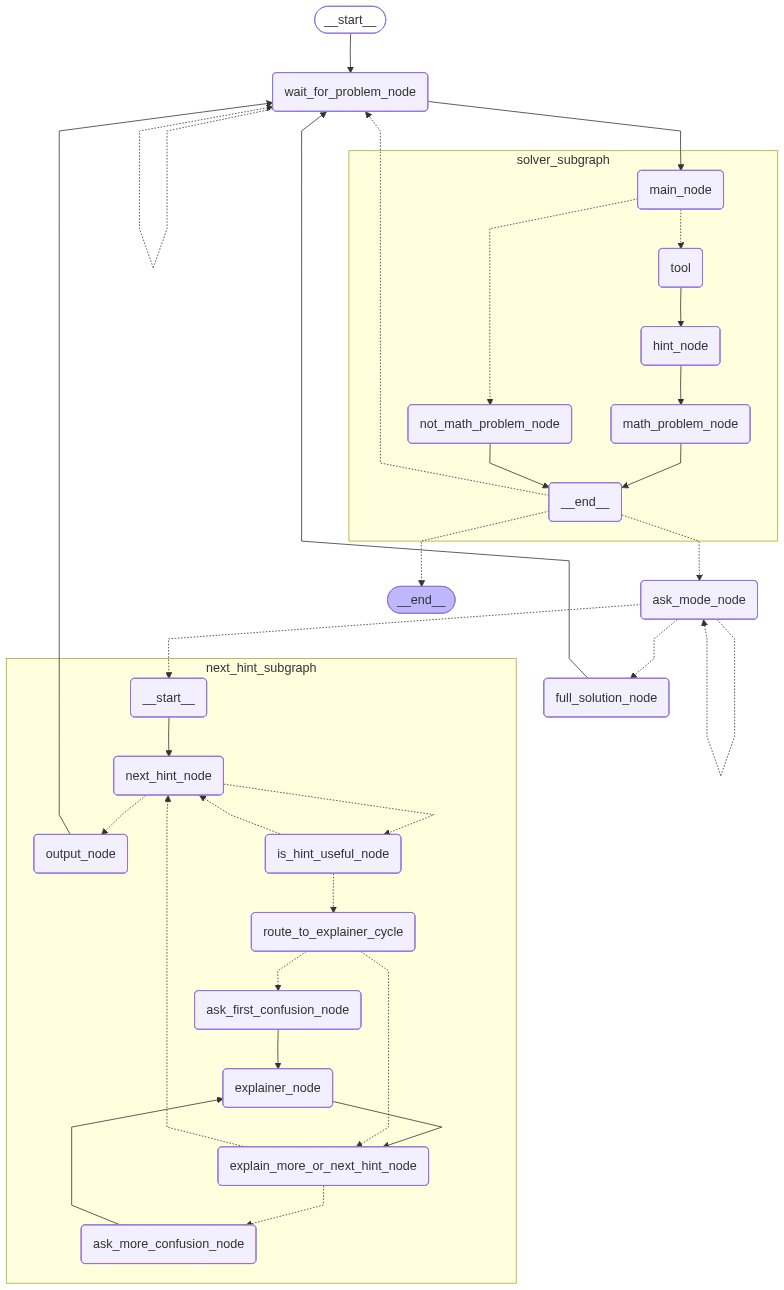

In [ ]:
graph.draw_graph(xray=True)

## Запускаем граф

In [ ]:
def run_graph_in_notebook(graph, thread_id, stream_mode=['updates']):

    # start graph
    for event in graph.stream_start(thread_id=thread_id):
        print(event["answer"])
        pending_interrupt = event["got_interrupt"]

    while True:
        user_text = input("> ")

        if user_text.strip().lower() in {"exit", "quit", "q"}:
            print("Выход.")
            break

        # запускаем шаг графа
        for event in graph.stream_events(
            user_message=user_text,
            pending_interrupt=pending_interrupt,
            thread_id=thread_id,
            stream_mode=stream_mode
        ):
            answer = event["answer"]
            print(answer)
            pending_interrupt = event["got_interrupt"]

In [ ]:
run_graph_in_notebook(graph, thread_id='1')



✏️ Пришли следующую задачу по математике.



KeyboardInterrupt



## gradio интерфейс

In [ ]:
import uuid
import gradio as gr

In [ ]:
class Interface:
    """
    Обёртка над Gradio-интерфейсом, которая принимает graph снаружи.
    """

    def __init__(self, graph: MathTutorGraph):
        self.graph = graph

    def on_submit(
        self,
        user_message: str,
        chat_history: list[dict],
        pending_interrupt: bool,
        thread_id: str,
    ):
        stream = self.graph.stream_events(
            user_message=user_message,
            pending_interrupt=pending_interrupt,
            thread_id=thread_id,
        )

        assistant_started = False
        got_interrupt = False

        for event in stream:
            answer = event["answer"]
            got_interrupt = event["got_interrupt"]

            if not assistant_started:
                chat_history = chat_history + [
                    {"role": "user", "content": user_message},
                    {"role": "assistant", "content": answer},
                ]
                assistant_started = True
            else:
                chat_history[-1]["content"] = answer

            yield chat_history, got_interrupt, thread_id

        # если граф вообще ничего не вернул
        if not assistant_started:
            chat_history = chat_history + [
                {"role": "user", "content": user_message},
                {"role": "assistant", "content": "(граф ничего не вернул)"},
            ]
            yield chat_history, got_interrupt, thread_id

    def on_load(
        self,
        chat_history: list[dict],
        pending_interrupt: bool,
        thread_id: str,
    ):
        # если по какой-то причине история уже есть — ничего не делаем
        if chat_history:
            return chat_history, pending_interrupt, thread_id

        init_stream = self.graph.stream_start(thread_id)

        answer = None
        got_interrupt = False

        for event in init_stream:
            answer = event["answer"]
            got_interrupt = event["got_interrupt"]

        if answer is not None:
            chat_history = chat_history + [
                {"role": "assistant", "content": answer}
            ]

        pending_interrupt = got_interrupt  # True — ждём ввод задачи

        return chat_history, pending_interrupt, thread_id

    def create_interface(self) -> gr.Blocks:
        with gr.Blocks() as demo:
            chatbot = gr.Chatbot(height=450, type="messages")
            textbox = gr.Textbox(label="Введите задачу или ответ на interrupt")
            send_btn = gr.Button("▶ Отправить")

            with gr.Row():
                yes_btn = gr.Button("✅ Да")
                no_btn = gr.Button("❌ Нет")

            with gr.Row():
                option1_btn = gr.Button("1️⃣ 1")
                option2_btn = gr.Button("2️⃣ 2")

            pending_interrupt_state = gr.State(False)
            thread_id_state = gr.State(str(uuid.uuid4()))

            # старт графа
            demo.load(
                fn=self.on_load,
                inputs=[chatbot, pending_interrupt_state, thread_id_state],
                outputs=[chatbot, pending_interrupt_state, thread_id_state],
            )

            # отправка сообщений
            send_btn.click(
                fn=self.on_submit,
                inputs=[textbox, chatbot, pending_interrupt_state, thread_id_state],
                outputs=[chatbot, pending_interrupt_state, thread_id_state],
            )

            textbox.submit(
                fn=self.on_submit,
                inputs=[textbox, chatbot, pending_interrupt_state, thread_id_state],
                outputs=[chatbot, pending_interrupt_state, thread_id_state],
            )

            # Да/Нет кнопки
            yes_btn.click(
                fn=self.on_submit,
                inputs=[gr.State("Да"), chatbot, pending_interrupt_state, thread_id_state],
                outputs=[chatbot, pending_interrupt_state, thread_id_state],
            )

            no_btn.click(
                fn=self.on_submit,
                inputs=[gr.State("Нет"), chatbot, pending_interrupt_state, thread_id_state],
                outputs=[chatbot, pending_interrupt_state, thread_id_state],
            )

            # 1 / 2 кнопки
            option1_btn.click(
                fn=self.on_submit,
                inputs=[gr.State("1"), chatbot, pending_interrupt_state, thread_id_state],
                outputs=[chatbot, pending_interrupt_state, thread_id_state],
            )

            option2_btn.click(
                fn=self.on_submit,
                inputs=[gr.State("2"), chatbot, pending_interrupt_state, thread_id_state],
                outputs=[chatbot, pending_interrupt_state, thread_id_state],
            )

        return demo

In [ ]:
demo = Interface(graph).create_interface()

In [ ]:
demo.launch(
    server_name="0.0.0.0",
    server_port=10003,
    share=True,
    debug=True,
    prevent_thread_lock=True,
)

* Running on local URL:  http://0.0.0.0:10003
* Running on public URL: https://71e57ecf107d7d554c.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Langfuse

Для старта работы с Langfuse вам потребуется сначала запустить langfuse сервис на своем устройстве.\
Используйте инструкцию через `docker-compose` по следующей ссылке:
https://langfuse.com/self-hosting/deployment/docker-compose

In [ ]:
from langfuse import Langfuse

import os
from dotenv import load_dotenv
ENV_PATH = '' # путь до файла .env с environment variables, где находятся необходимые для langfuse переменные (см. следующую ячейку)
load_dotenv(ENV_PATH)

True

In [ ]:
langfuse = Langfuse(
    public_key=os.getenv("LANGFUSE_PUBLIC_KEY"),
    secret_key=os.getenv("LANGFUSE_SECRET_KEY"),
    host=os.getenv("LANGFUSE_HOST"),
)

In [ ]:
def run_graph_in_notebook_with_langfuse(graph, thread_id: str, callbacks=None):
    # создаём trace_id, к которому можно привязывать span'ы
    trace_id = langfuse.create_trace_id()

    pending_interrupt = False

    # используем контекстный менджер для логирования первоначального ответа юзеру (как только он открыл чат)
    with langfuse.start_as_current_span(
        name="start_math_tutor_session",
        trace_context={"trace_id": trace_id}
    ) as start_span:
        start_span.update_trace(
            name="math_tutor_session",
            session_id=thread_id,
        )
        for event in graph.stream_start(thread_id=thread_id):
            answer = event["answer"]
            print(answer)
            pending_interrupt = event["got_interrupt"]

        start_span.update(
            input={},
            output=answer
        )

    turn_idx = 0
    while True:
        user_text = input("> ")

        if user_text.strip().lower() in {"exit", "quit", "q"}:
            break

        # используем контекстный менджер для логирования ввода юзера и ответа чат-бота каждый раз,
        # когда вызывается interrupt-нода
        turn_idx += 1
        with langfuse.start_as_current_span(
            name=f"turn_{turn_idx}",
            trace_context={"trace_id": trace_id}
        ) as turn_span:
            turn_span.update_trace(
                name="math_tutor_session",
                session_id=thread_id,
            )
            for event in graph.stream_events(
                user_message=user_text,
                pending_interrupt=pending_interrupt,
                thread_id=thread_id,
                callbacks=callbacks
            ):
                answer = event["answer"]
                print(answer)
                pending_interrupt = event["got_interrupt"]

                turn_span.update(input=user_text, output=answer)

In [ ]:
from langfuse.langchain import CallbackHandler

In [ ]:
cb_handler = CallbackHandler(public_key=os.getenv("LANGFUSE_PUBLIC_KEY"))
cb_handler

Каждый запуск ноды/цепочки/LLM внутри графа вызывает callbacks: on_runnable_start / on_runnable_end, on_llm_start / on_llm_end и т.д.

In [ ]:
run_graph_in_notebook_with_langfuse(graph, thread_id='4', callbacks=cb_handler)



✏️ Пришли следующую задачу по математике.


>  sinx = 12






Как ты хочешь решить задачу?

1. С подсказками
2. Выдать сразу полное решение


>  2




⚪️ Выдано полное решение без подсказок

Полное решение:

1. The equation given is $$\sin x = 12$$.
2. The sine function, $$\sin x$$, has a range of $$[-1, 1]$$. This means the output of $$\sin x$$ can only be between -1 and 1, inclusive.
3. Since 12 is outside this range, there is no real value of $$x$$ for which $$\sin x = 12$$.
4. Therefore, the equation $$\sin x = 12$$ has no solution in the real numbers.

$$\boxed{\text{No solution}}$$

✏️ Пришли следующую задачу по математике.


## fastapi example

Предполагается, что вы уже запустили FastAPI-приложение из репозитория.\
Сделаем первый проверочный запрос к эндпоинту `/health`, чтобы убедиться, что сервис доступен.

In [ ]:
import requests

ip = "IP_ADDRESS_OF_YOUR_FASTAPI_APP"
port = "PORT_OF_YOUR_FASTAPI_APP"
url = f"http://{ip}:{port}/health"

response = requests.get(url)
print(response)
print("Status code:", response.status_code)
print("JSON:", response.json())

<Response [200]>
Status code: 200
JSON: {'status': 'ok'}
